<a href="https://colab.research.google.com/github/Suzukuru/MathToolsforNeuroscience_PSets/blob/main/Week1Tutorial2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 2

**Linear Algebra I: Vectors**

**Kuru**

**Important reminders**: Before starting, click "File -> Save a copy in Drive". Produce a pdf for submission by "File -> Print" and then choose "Save to PDF".

To complete this tutorial, you should have watched Video 1.1: Vectors, Video 1.2: Vector operations, and Video 1.3: Vector spaces.


In [1]:
%pip install ipywidgets jupyterlab_widgets
# Imports
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import ipywidgets as widgets

# Plotting parameters
matplotlib.rcParams.update({'font.size': 22})

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 37.0 MB/s  0:00:00


# Exercise 1: Figuring out a basis

Let's say we are looking at the firing rates of 3 neurons. We can represent their activity in a 3D plot, as below. It turns out that due to their tightly-linked interactions, they always fire in such a way that the point in 3D space falls along a 2D plane (that passes through the origin). Basically, every single data point we record of the firing rates of the 3 neurons falls on that plane. This is represented by the blue plane in the figure below. This 2D plane is a subspace of all of 3-D space (R3).

A) How many basis vectors would you need for the 2D plane? How many components would each basic vector have?

B) How many numbers would you need to be able to fully describe the state of the 3 neuron population at a given time?


# Initial Answer
A. It depends what is being asked, only a 2D plane or a 2D plane subspace inside of 3D space? If its the former then only 2 basis vectors and components, while for the latter its 2 basis vectors and 3 components. The number of rows dictate the actual space the vector lives in while the columns tell you the number of steps it takes in that space. So in the first example the vector lives in 2D and moves in 2 steps only, while the second example lives in 3D and moves in 2 steps also. Because the vector can only move twice, all the linear combinations is bounded inside a 2D plane as true 3D movement requires three unique directions. \
\
In short, 2 basis vectors and 3 components for each vector. The components dictate the output space, while the two basis vectors tell it where it lands in that space, which is a 2D plane as it can only move in two unique directions.\
\
B. You only need the two basis vectors to fully describe the state of the model as one of the neuron's firing rates is just a linear combination of those two.

# Answer after feedback
A. It's 2 basis vectors and 3 components. \
\
The number of rows dictate the output space the vector inhabits while the number of columns dictate the number of steps it takes in the space. So the vectors moves in 3D (three unique steps in space) but the linear combination of these vectors only take 2 unique steps inside 3D space. As a result, the linear combination of the 2 basis evectors is bounded inside a 2D plane, because full 3D movement requires 3 unique steps inside 3D. \
\
One way I visualize it myself is, say there's stairs to the second floor and the basement in front of me. I can only go up the stairs and never down the basement because the two basis vectors always lands me upwards when I go forward. Likewise I can only go downwards if I take a step backwards. You can only move in a tilted ramp because thats the only direction your allowed to go in. If I had one more unique step in 3D I could've covered not only the basement but all of 3D space. \
\
In short, two basis vectors live in R^3 (one commponent per neuron) and the two linearly independent vectors can only combine to reach points in a plane since covering all of 3D spacers requires another independent direction. \
\
B. It only requires two numbers or coefficient to describe the whole state, c1v1 + c2v2. The third degree of freedom collapses as the neurons firing rate is constrained to a plane.

 Execute this cell to see figure


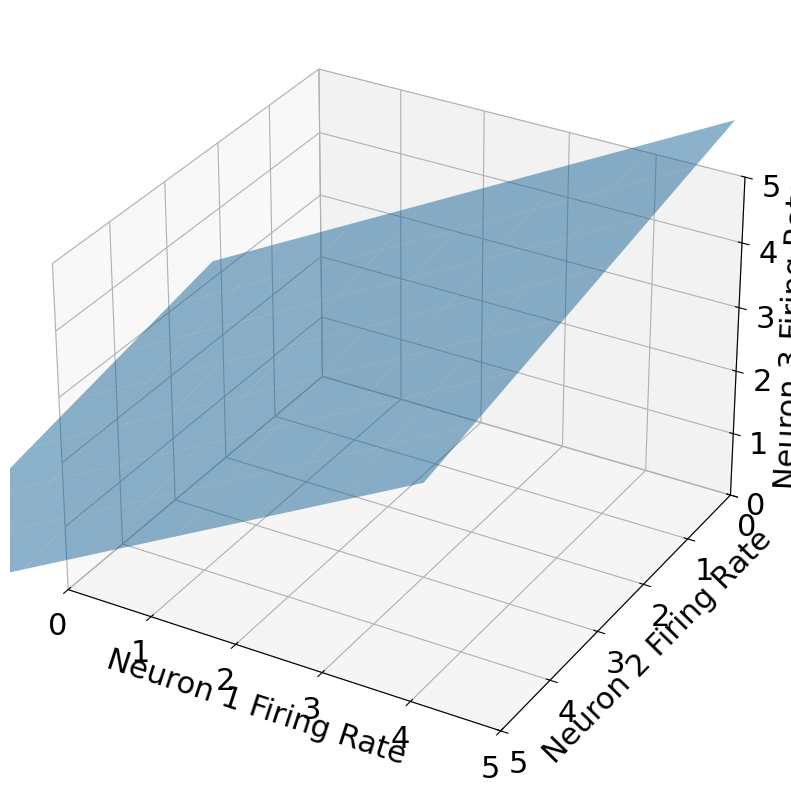

In [2]:
# @markdown Execute this cell to see figure

fig = plt.figure(figsize = (10, 10))

# add axes
ax = fig.add_subplot(111,projection='3d')

xx, yy = np.meshgrid(range(-4, 4), range(-4, 4))
z = .7*xx + -.2*yy

# plot the plane
ax.plot_surface(xx, yy, z, alpha=0.5)

ax.set(xlim = [0, 5], ylim = [5, 0], zlim = [0, 5], xlabel = 'Neuron 1 Firing Rate',  ylabel = 'Neuron 2 Firing Rate', zlabel = 'Neuron 3 Firing Rate');
#ax.invert_xaxis()


# Exercise 2: Determing dependence

Let's say we have four vectors:

$$ \mathbf{a} = \begin{bmatrix}
    4 \\ 2 \\ 0
\end{bmatrix},  \mathbf{b} = \begin{bmatrix}
    1 \\ 0 \\ 3,
\end{bmatrix}, \mathbf{c} = \begin{bmatrix}
    5 \\ 2 \\ 3
\end{bmatrix}, \mathbf{d} = \begin{bmatrix}
    3 \\ 3 \\ 2
\end{bmatrix}$$

Check out this visualization prepared by Oğul Can Yurdakul to better see the vectors: https://www.geogebra.org/3d/hherq78z!

1. Are these vectors linearly independent or dependent? Why?
2. What is the span of the set of vectors $\{\mathbf{a}, \mathbf{b}, \mathbf{c}, \mathbf{d}\}$?
3. What is the span of the set of vectors $\{\mathbf{a}, \mathbf{b}, \mathbf{c}\}$?
4. What is the span of a set just consisting of vector $\{\mathbf{a}$} (in general terms)?
5. What is the span of the set of vectors $\{\mathbf{a}, \mathbf{b}$} (in general terms)?

1. The vectors are linearly dependent because can be expressed as c = a+b.
2. The span is ℝ³ exactly, as outputs of span(a,b,c,d) occupies all of 3D space as a, b and d are linearly independent. Since a, b, d covers all of ℝ³, there must be one dependent vector which is c.
3. The span is a plane subspace inside of ℝ³, as the outputs of span(a,b,c).only create a plane inside of ℝ³ because c is a linear combination of a and b.
4. The span is a line inside of ℝ³, as outputs of span(a) create a line inside of ℝ³.
5. The span is a plane inside of ℝ³ as outputs of span(a,b) create a plane inside of ℝ³.

## A) Linear independence vs dependence
Are these vectors linearly independent or dependent? Why?


The vectors are linearly dependent because can be expressed as c = a+b. You can also tell if you solve for the rank.

In [9]:
matrix = np.array([[4, 1, 5, 3],
                   [2, 0, 2, 3],
                   [0, 3, 3, 2]])
print(np.linalg.matrix_rank(matrix))

3


## B) Orthogonal vectors
Are vectors $\bar{a}$ and $\bar{b}$ orthogonal? How do you know?

a and b are not orthogonal because the dot product results in 4 not 0.

In [3]:
a = np.array([4, 2, 0])
b = np.array([1, 0 , 3])
print(a @ b)

4


## C) Span

i) What is $Span\{\bar{a}, \bar{b}, \bar{c}, \bar{d}\}$?

ii) What is $Span\{\bar{a}, \bar{b}, \bar{c}\}$?

iii) What is $Span\{\bar{a}\}$?

1. The span is R^3 exactly, as outputs of span(a,b,c,d) occupies all of 3D space as a, b and d are linearly independent. Since a, b, d covers all of R^3, there must be one dependent vector which is c. \
Span{a, b, c, d} = {c₁a + c₂b + c₃c + c₄d | c₁, c₂, c₃, c₄ ∈ ℝ} = ℝ³

2. The span is a plane subspace inside of R^3, as the outputs of span(a,b,c).only create a plane inside of R^3 because c is a linear combination of a and b. \
Span{a, b, c} = {c₁a + c₂b + c₃c | c₁, c₂, c₃ ∈ ℝ} = a plane through the origin in ℝ³

3. The span is a line inside of R^3, as outputs of span(a) create a line inside of R^3. \
Span{a} = {c₁a | c₁ ∈ ℝ} = a line through the origin in ℝ³

## D) Basis

Can you make a basis for $R^3$ based on the above vectors? What is it?

Span{a, b, d} = {c₁a + c₂b + c₃d | c₁, c₂, c₃ ∈ ℝ} = ℝ³ = basis of ℝ³

# (Optional, advanced) Exercise 3: Vector Projections

We want to find the projection of one vector onto another, by which we essentially mean the component of a vector that lies along another vector. For two vectors $\bar{a}$ and $\bar{b}$, can you come up with the formula (and proof of that formula) for the projection of $\bar{b}$ onto $\bar{a}$ (the green vector below)?


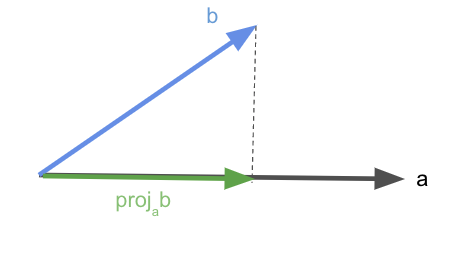

## Formula for $\bar p$
### Setup

$$\bar p = \bar b + \bar c, \qquad \bar p = \|\bar p\|\,\hat a$$

  The core idea here is $\bar p = \|\bar p\|\,\hat a$, where we make the length of the projection point in a's direction by using its unit vector.

### Length of the projection (right triangle)

$$\cos\theta = \frac{\|\bar p\|}{\|\bar b\|} \;\Rightarrow\; \|\bar p\| = \|\bar b\|\cos\theta$$

Now let's assume p and c form a right triangle, we can use basic trig rules (CAH) to get a formula for the length of p.

### Writing cos θ with the dot product

$$\bar a \cdot \bar b = \|\bar a\|\,\|\bar b\|\cos\theta \;\Rightarrow\; \cos\theta = \frac{\bar a \cdot \bar b}{\|\bar a\|\,\|\bar b\|}$$

Here we found a substitute for $\cos\theta$ from $\bar a \cdot \bar b$ that doesn't contain the unknown (p) itself in it so it doesn't become circular since $\bar p \cdot \bar b$ is also valid substitution for $\cos\theta$.

### Substitute into the length

$$\|\bar p\| = \|\bar b\| \cdot \frac{\bar a \cdot \bar b}{\|\bar a\|\,\|\bar b\|} = \frac{\bar a \cdot \bar b}{\|\bar a\|}$$

### Direction of a

$$\hat a = \frac{\bar a}{\|\bar a\|}$$

Expand the definition of a unit vector

### Projection vector

$$\bar p = \|\bar p\|\,\hat a = \frac{\bar a \cdot \bar b}{\|\bar a\|}\cdot\frac{\bar a}{\|\bar a\|} = \frac{\bar a\,(\bar a \cdot \bar b)}{\|\bar a\|^2} = \frac{\bar a \cdot \bar b}{\bar a \cdot \bar a}\,\bar a$$

Now there's the formual for the projection of b onto a.

*Note: this only simplifies to $(\bar a \cdot \bar b)\,\bar a$ if $\bar a$ is a unit vector, since then $\bar a \cdot \bar a = 1$. In general the denominator stays.*

## Proof that c is perpendicular to a
Since c and a forming a right triangle was assumed so we can apply basic trig, its important to prove that a and c is indeed perpendicular by using our new formula to solve for c then proving by solving for $\bar a \cdot \bar c = 0$

Let $\bar a = \begin{bmatrix} 4 \\ 0 \end{bmatrix}$, $\bar b = \begin{bmatrix} 3 \\ 3 \end{bmatrix}$

$$\bar a \cdot \bar b = 4(3) + 0(3) = 12, \qquad \bar a \cdot \bar a = 4(4) + 0(0) = 16$$

$$\bar p = \frac{\bar a \cdot \bar b}{\bar a \cdot \bar a}\,\bar a = \frac{12}{16}\begin{bmatrix} 4 \\ 0 \end{bmatrix} = \frac{3}{4}\begin{bmatrix} 4 \\ 0 \end{bmatrix} = \begin{bmatrix} 3 \\ 0 \end{bmatrix}$$

$$\bar c = \bar p - \bar b = \begin{bmatrix} 3 \\ 0 \end{bmatrix} - \begin{bmatrix} 3 \\ 3 \end{bmatrix} = \begin{bmatrix} 0 \\ -3 \end{bmatrix}$$

$$\bar a \cdot \bar c = 4(0) + 0(-3) = 0 \;\Rightarrow\; \bar c \perp \bar a$$